<a href="https://colab.research.google.com/github/ja2faded/L01-cv/blob/main/L1Group3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision

Let's do some very basic computer vision. We're going to import the MNIST handwritten digits data and $k$NN to predict values (i.e. "see/read").

1. To load the data, run the following code in a chunk:
```
import pickle
with open('data/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']
```
The `y_test` and `y_train` vectors, for each index `i`, tell you want number is written in the corresponding index in `X_train[i]` and `X_test[i]`. The value of `X_train[i]` and `X_test[i]`, however, is a 28$\times$28 array whose entries contain values between 0 and 256. Each element of the matrix is essentially a "pixel" and the matrix encodes a representation of a number. To visualize this, run the following code to see the first ten numbers:
```
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()
```
OK, those are the data: Labels attached to handwritten digits encoded as a matrix.

2. What is the shape of `X_train` and `X_test`? What is the shape of `X_train[i]` and `X_test[i]` for each index `i`? What is the shape of `y_train` and `y_test`?
3. Use Numpy's `.reshape()` method to covert the training and testing data from a matrix into an vector of features. So, `X_test[index].reshape((1,784))` will convert the $index$-th element of `X_test` into a $28\times 28=784$-length row vector of values, rather than a matrix. Turn `X_train` into an $N \times 784$ matrix $X$ that is suitable for scikit-learn's kNN classifier where $N$ is the number of observations and $784=28*28$ (you could use, for example, a `for` loop).
4. Use the reshaped `X_test` and `y_test` data to create a $k$-nearest neighbor classifier of digit. What is the optimal number of neighbors $k$? If you can't determine this, play around with different values of $k$ for your classifier.
5. For the optimal number of neighbors, how well does your predictor perform on the test set? Report the accuracy, compute a confusion matrix, and explain your findings.
6. For your confusion matrix, which mistakes are most likely? Do you find any interesting patterns?
7. So, this is how computers "see." They convert an image into a matrix of values, that matrix becomes a vector in a dataset, and then we deploy ML tools on it as if it was any other kind of tabular data. To make sure you follow this, invent a way to represent a color photo in matrix form, and then describe how you could convert it into tabular data. (Hint: RGB color codes provide a method of encoding a numeric value that represents a color.)

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jackson Gayeski, Derek Hatherley, Will Morales, Abdullah Rana

**Date:** November 4th, 2026

In [ ]:
import pickle
with open('/content/minst.pkl', 'rb') as f:
    data = pickle.load(f)
X_train, y_train = data['X_train'], data['y_train']
X_test, y_test = data['X_test'], data['y_test']

7 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  84 185 159 151  60  36   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0 222 254 254 254 254 241 198 198 198 198 198 198 19

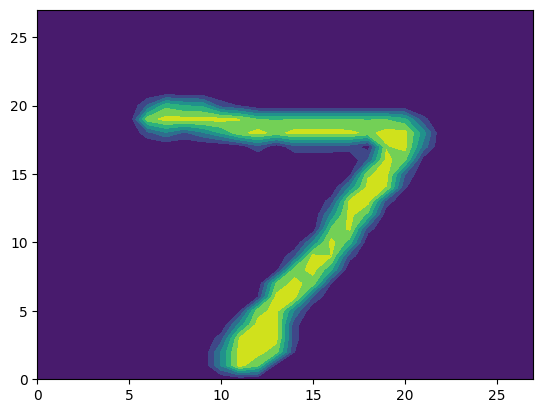

2 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 116 125 171 255 255 150  93   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0 169 253 253 253 253 253 253 218  30   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0 169 253 253 253 213 142 176 253 253 122   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  52 250 253 210  32  12   0   6 206 253 140   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  77 251 210  25   0   0   0 122 248 253  65   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  31  18   0   0   0   0 209 253 253  65   

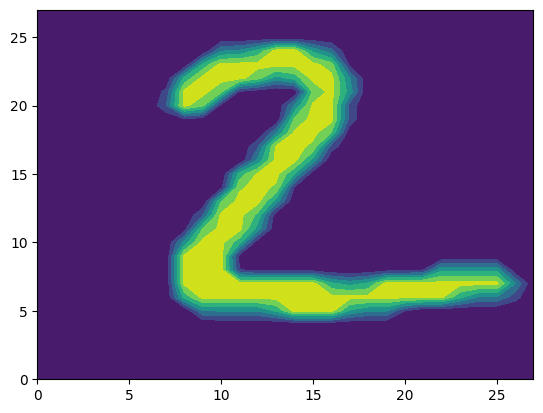

1 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  38 254 109   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  87 252  82   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0 135 241   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  45 244 150   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  84 254  63   

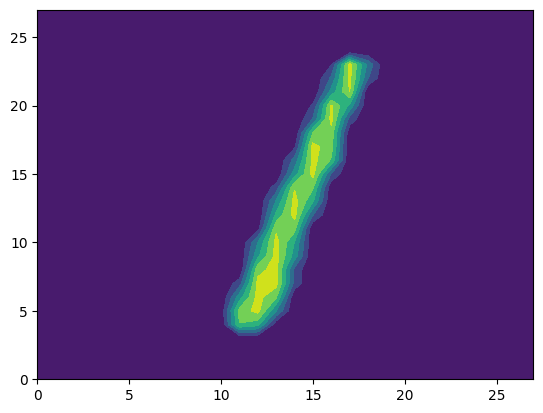

0 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  11 150 253 202  31   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  37 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0  21 197 251 251 253 107   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 110 190 251 251 251 253 169 109  62   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 253 251 251 251 251 253 251 251 22

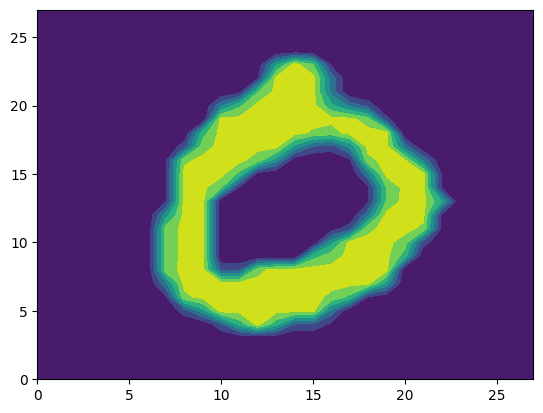

4 

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  50 224   0   0   0   0   0   0   0  70  29   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0 121 231   0   0   0   0   0   0   0 148 168   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   4 195 231   0   0   0   0   0   0   0  96 210  11   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  69 252 134   0   0   0   0   0   0   

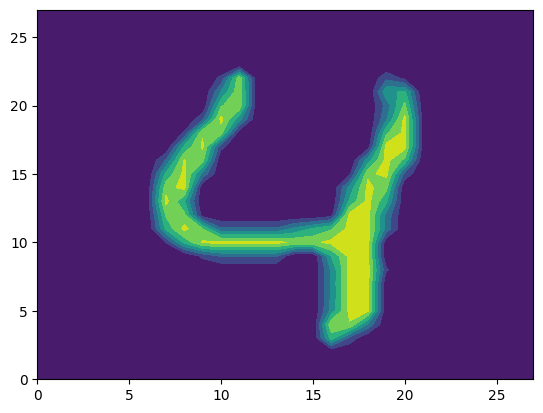

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
np.set_printoptions(edgeitems=30, linewidth=100000)
for i in range(5):
    print(y_test[i],'\n') # Print the label
    print(X_test[i],'\n') # Print the matrix of values
    plt.contourf(np.rot90(X_test[i].transpose())) # Make a contour plot of the matrix values
    plt.show()



In [ ]:
#q2
print('X_train: ', X_train.shape)
print('X_test: ', X_test.shape)
print('X_train[i]: ', X_train[0].shape)
print('X_test[i]: ', X_test[0].shape)
print('y_train: ', y_train.shape)
print('y_test: ', y_test.shape)

X_train:  (60000, 28, 28)
X_test:  (10000, 28, 28)
X_train[i]:  (28, 28)
X_test[i]:  (28, 28)
y_train:  (60000,)
y_test:  (10000,)


In [ ]:
#q3
train_rows = []
for i in range(len(X_train)):
  train_rows.append(X_train[i].reshape(784))
X_train_flat = np.array(train_rows)

test_rows = []
for i in range(len(X_test)):
  test_rows.append(X_test[i].reshape(784))
X_test_flat = np.array(test_rows)


print("Train dimension before: ", X_train.shape)
print("Train dimensions after: ", X_train_flat.shape)
print("Test dimensions before: ", X_test.shape)
print("Test dimensions after: ", X_test_flat.shape)


Train dimension before:  (60000, 28, 28)
Train dimensions after:  (60000, 784)
Test dimensions before:  (10000, 28, 28)
Test dimensions after:  (10000, 784)


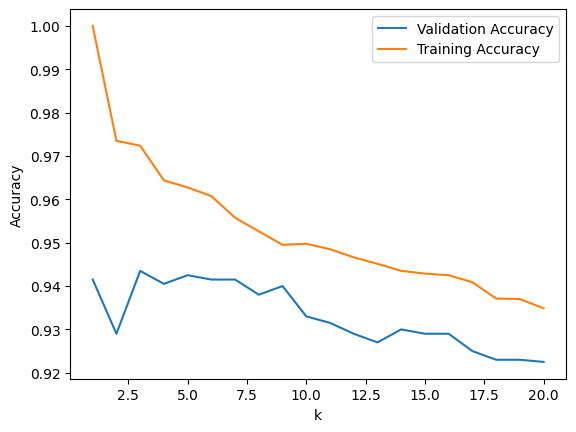


Optimal k: 3
Validation accuracy at optimal k: 0.9435


In [ ]:
#q4
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier

# Runitime was too long with entire set, so using 10,000 random images
eval_X_sub, _, eval_y_sub, _ = train_test_split(X_train_flat, y_train, train_size=10000, random_state=42, stratify=y_train)
# split into training and testing sets
eval_X_tr, eval_X_valid, eval_y_tr, eval_y_valid = train_test_split(eval_X_sub, eval_y_sub, train_size=0.8, random_state=42)

eval_scaler = MinMaxScaler()
eval_X_train_scaled = eval_scaler.fit_transform(eval_X_tr)
eval_X_valid_scaled = eval_scaler.transform(eval_X_valid)

eval_ks = np.arange(1,21) # runtime extremely long for large range
eval_valid_acc = []
eval_train_acc = []
for eval_k in eval_ks:
  eval_candidate = KNeighborsClassifier(n_neighbors=int(eval_k))
  eval_candidate.fit(eval_X_train_scaled, eval_y_tr)
  eval_valid_hat = eval_candidate.predict(eval_X_valid_scaled)
  eval_train_hat = eval_candidate.predict(eval_X_train_scaled)
  eval_valid_acc.append(np.mean(eval_y_valid == eval_valid_hat))
  eval_train_acc.append(np.mean(eval_y_tr == eval_train_hat))

# determine best k value
eval_best_k = int(eval_ks[np.argmax(eval_valid_acc)])

plt.plot(eval_ks, eval_valid_acc, label='Validation Accuracy')
plt.plot(eval_ks, eval_train_acc, label='Training Accuracy')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

print()
print(f'Optimal k: {eval_best_k}')
print(f'Validation accuracy at optimal k: {max(eval_valid_acc)}')

# Best k among 1 through 20 on this validation split is 3




In [ ]:
#q5
import pandas as pd

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train_flat)
X_test_scaled = scaler.transform(X_test_flat)

#refit for the full training set eith the optimal k from ^
model = KNeighborsClassifier(n_neighbors=eval_best_k)
model.fit(X_train_scaled, y_train)
y_hat = model.predict(X_test_scaled)

test_acc = np.mean(y_test == y_hat)
print(f'Test accuracy at k = {eval_best_k}: {test_acc}')

#confusion matrix
cm = pd.crosstab(y_test, y_hat, rownames=['Actual'], colnames=['Predicted'])
print(cm)

#With k = 3 and the full training set, test accuracy was 0.9705, which is
#higher than the .9435 validation accuracy in Q4. Using all 60,000 training
#images likely helped, but the validation and test images also differ, so the
#increase cannot be attributed entirely to the larger training set. Most
#predictions fall on the main diagonal of the confusion matrix, so errors are rare.

Test accuracy at k = 3: 0.9705
Predicted    0     1    2    3    4    5    6    7    8    9
Actual                                                      
0          974     1    1    0    0    1    2    1    0    0
1            0  1133    2    0    0    0    0    0    0    0
2           10     9  996    2    0    0    0   13    2    0
3            0     2    4  976    1   13    1    7    3    3
4            1     6    0    0  950    0    4    2    0   19
5            6     1    0   11    2  859    5    1    3    4
6            5     3    0    0    3    3  944    0    0    0
7            0    21    5    0    1    0    0  991    0   10
8            8     2    4   16    8   11    3    4  914    4
9            4     5    2    8    9    2    1    8    2  968


In [ ]:
#q6

#find most common mistakes
mistakes = []
for i in range(10):
  for j in range(10):
    if i != j:
      mistakes.append((cm.loc[i, j], i, j))
mistakes.sort(reverse=True) #rank the mistakes

print('Most common mistakes (actual, predicted):')
for m in mistakes[:5]:
  print(m[1], 'predicted as', m[2], ':', m[0], 'times')

#recall for each digit
print()
for d in range(10):
  print(d, ':', cm.loc[d, d] / cm.loc[d].sum())
  #The most common mistakes were 7 as 1 (21 times), 4 as 9 (19 times), and 8 as 3
  #(16 times), all digits that look similar when written sloppily. 1 and 0 were
  #easiest (over 99%), and 8 was hardest (93.8%). kNN only compares pixel
  #positions, so digits that share a lot of the same pixels get confused with each other.

Most common mistakes (actual, predicted):
7 predicted as 1 : 21 times
4 predicted as 9 : 19 times
8 predicted as 3 : 16 times
3 predicted as 5 : 13 times
2 predicted as 7 : 13 times

0 : 0.9938775510204082
1 : 0.9982378854625551
2 : 0.9651162790697675
3 : 0.9663366336633663
4 : 0.9674134419551935
5 : 0.9630044843049327
6 : 0.9853862212943633
7 : 0.9640077821011673
8 : 0.9383983572895277
9 : 0.9593657086223984


### Q7

I would represent a color photo with three matrices: one for red, one for green, and one for blue. For an 8-bit RGB image, each value is between 0 and 255 and tells us how much of that color is present at a pixel. For example, `(255, 0, 0)` is red, `(0, 0, 0)` is black, and `(255, 255, 255)` is white. Together, the three matrices form an array with shape `(height, width, 3)`.

To turn this into tabular data, I would read the pixels row by row, keeping the red, green, and blue values together for each pixel. The columns would be `pixel1_R`, `pixel1_G`, `pixel1_B`, `pixel2_R`, and so on. Each photo becomes one row with `height * width * 3` features. A 28 by 28 color photo would therefore have 2,352 features instead of the 784 used for a grayscale MNIST image.

For N photos, I would resize them to the same height and width and flatten each one in the same order, giving a table with shape `(N, height * width * 3)`. The image labels would be kept separately as `y`, just like the digit labels here. We could then train a kNN classifier using the RGB values as features.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]